<a href="https://colab.research.google.com/github/Aranzazu21/Machine-Learning/blob/main/Reporte_de_Pr%C3%A1ctica_P3P1_Regresi%C3%B3n_Lineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Ecuaciones y afirmaciones
Ecuación: Peso = 80.2640 + (-0.0362 * Días) + (0.1093 * Km)
Afirmación 1: El peso base estimado (intercepto) es de 80.26 kg.
Afirmación 2: Por cada día transcurrido, el peso cambia en promedio -0.0362 kg.
Afirmación 3: Por cada kilómetro extra en mtb, el peso cambia en promedio 0.1093 kg.

Metricas en conjunto de pruebas
R2: -4.0826 (El modelo explica el -408.26% de la variabilidad)
MAE: 5.8914 kg (Margen de error promedio)
RMSE: 6.0779 kg

Prediccion en un escenario nuevo
Bajo un escenario de 200 días y 50 km, el peso estimado es: 78.49 kg


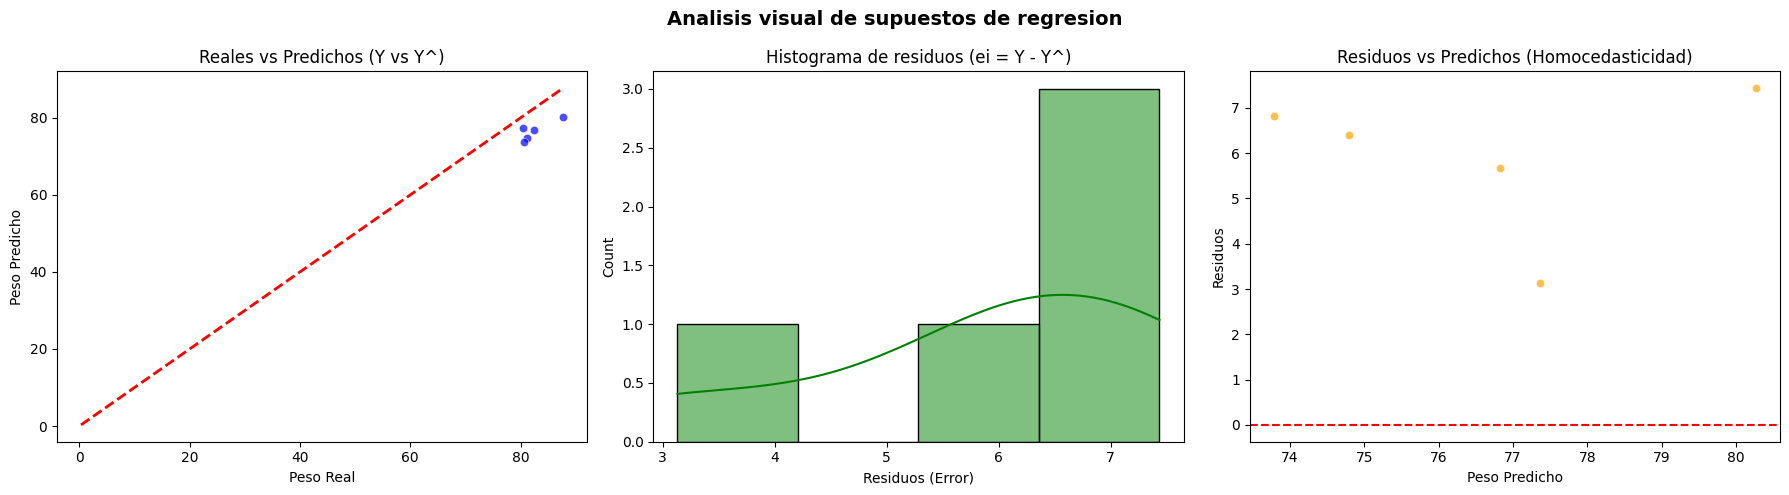

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import drive
import warnings
warnings.filterwarnings('ignore')


drive.mount('/content/drive')


ruta = '/content/drive/MyDrive/Ciencia de datos /dataset_limpio_transformado (2).xlsx'
df = pd.read_excel(ruta)
df['Fecha_DT'] = pd.to_datetime(df['Fecha_DT'])
df = df.sort_values('Fecha_DT').reset_index(drop=True)

df['Dias_Transcurridos'] = (df['Fecha_DT'] - df['Fecha_DT'].min()).dt.days
df['carga_semanal_km'] = df['carga_semanal_km'].fillna(0)
df['Peso_Kg'] = df['Peso_Kg'].fillna(df['Peso_Kg'].mean())

X = df[['Dias_Transcurridos', 'carga_semanal_km']]
y = df['Peso_Kg']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


modelo_lineal = LinearRegression().fit(X_train, y_train)
y_pred = modelo_lineal.predict(X_test)


r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

b0 = modelo_lineal.intercept_
b1 = modelo_lineal.coef_[0]
b2 = modelo_lineal.coef_[1]

# Resultados
print("\nEcuaciones y afirmaciones")
print(f"Ecuación: Peso = {b0:.4f} + ({b1:.4f} * Días) + ({b2:.4f} * Km)")
print(f"Afirmación 1: El peso base estimado (intercepto) es de {b0:.2f} kg.")
print(f"Afirmación 2: Por cada día transcurrido, el peso cambia en promedio {b1:.4f} kg.")
print(f"Afirmación 3: Por cada kilómetro extra en mtb, el peso cambia en promedio {b2:.4f} kg.")

print("\nMetricas en conjunto de pruebas")
print(f"R2: {r2:.4f} (El modelo explica el {r2*100:.2f}% de la variabilidad)")
print(f"MAE: {mae:.4f} kg (Margen de error promedio)")
print(f"RMSE: {rmse:.4f} kg")

print("\nPrediccion en un escenario nuevo")
dias_futuro = 200
km_futuro = 50
peso_pred = modelo_lineal.predict([[dias_futuro, km_futuro]])
print(f"Bajo un escenario de {dias_futuro} días y {km_futuro} km, el peso estimado es: {peso_pred[0]:.2f} kg")

# Visualización de supuestos
residuos = y_test - y_pred

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Analisis visual de supuestos de regresion', fontweight='bold', fontsize=14)

# Reales vs Predichos
sns.scatterplot(x=y_test, y=y_pred, ax=axs[0], alpha=0.7, color='blue')
axs[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
axs[0].set_title('Reales vs Predichos (Y vs Y^)')
axs[0].set_xlabel('Peso Real')
axs[0].set_ylabel('Peso Predicho')

# Histograma de residuos
sns.histplot(residuos, kde=True, ax=axs[1], color='green')
axs[1].set_title('Histograma de residuos (ei = Y - Y^)')
axs[1].set_xlabel('Residuos (Error)')

# Residuos vs Predichos
sns.scatterplot(x=y_pred, y=residuos, ax=axs[2], color='orange', alpha=0.7)
axs[2].axhline(0, color='r', linestyle='--')
axs[2].set_title('Residuos vs Predichos (Homocedasticidad)')
axs[2].set_xlabel('Peso Predicho')
axs[2].set_ylabel('Residuos')

plt.tight_layout()
plt.show()